# Challenge 5: severe-delay risk (main target) and runway arrival capacity (bonus), 3–12 h ahead

Following the organisers' update of 31 Oct 2026 (12:45):

1. **Main target: will this ATL/DFW flight be delayed more than 45 minutes?** `DEP_DELAY > 45` for departures from the hub, `ARR_DELAY > 45` for arrivals into it. About 10–15% of flights are positive, so we report **precision, recall, F1 and PR-AUC**, not just accuracy.
2. **Bonus: arrival capacity (AAR)**, the number of aircraft landing each hour, scored with **RMSE**. Measured from the full BTS data, since the provided file is a ~1% sample.

**Weather rule (organisers):** only weather observed **at least 3 hours before** the scheduled time. Every row has an issue time `T = scheduled hour − lead` (lead 3–12 h), and the organisers' hourly weather file is joined at T. An assert checks this on every flight row.

**The rule:** for a forecast issued at time `T = target hour − lead`, every input must be **observed or issued at or before T**. That means the TAF that existed at T, the LAMP run that existed at T, the METAR at T, the published schedule, and only flights that had already moved by T. `c5lib.build_aar_table()` enforces this with asserts.

**Why gradient-boosted trees (LightGBM):** the inputs are a few dozen mixed tabular signals (categories, thresholds, wind components) with strong interactions, such as "thunderstorm forecast × busy arrival bank". Trees handle that well, train in seconds, and give per-prediction feature contributions for the dashboard's evidence panel. A deep sequence model would add little on 18 months of hourly data and would be harder to explain to a controller.

**Honesty checks built in:** four baselines, an ablation by data source, a time-based split, a test on an airport the model never saw (**ORD**), calibrated uncertainty bands, a failure analysis, and storm-event warning lead times.

| Split | Target hours (UTC) | Used for |
|---|---|---|
| train | 2023-01-02 → 2024-06-30 | fitting |
| val | 2024-07-01 → 2024-12-31 | early stopping, calibration, conformal bands |
| **test** | **2025-01-01 → 2025-07-30** | **reported numbers only** |

## 0. Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path("src").resolve()))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
import joblib
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

import c5lib as C
from c5lib import (TRAIN_AIRPORTS, HOLDOUT_AIRPORTS, LEADS, SPLITS, FEATURE_GROUPS, AAR_FEATURES,
                   CLF_FEATURES, CLF_GROUPS, MODEL_DIR, EXT)

C.MODEL_DIR.mkdir(parents=True, exist_ok=True)
AIRPORTS = TRAIN_AIRPORTS + HOLDOUT_AIRPORTS
HEADINGS = {a: C.runway_heading(a) for a in AIRPORTS}
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
METRICS = {}
print("Runway headings used:", HEADINGS)

Runway headings used: {'KATL': 80.0, 'KDFW': 180.0, 'KORD': 90.0}


## 1. Full flight data (BTS) and a check against the provided file

`scripts/download_data.py` fetched every BTS on-time record for flights touching ATL, DFW or ORD (Jan 2023 – Jul 2025). The provided challenge file is a ~1% sample of the same source. We confirm the two agree before relying on the full data.

In [2]:
files = sorted(C.bts_dir(AIRPORTS).glob("bts_*.parquet"))
flights = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
flights = flights[flights.CRS_ELAPSED_TIME.notna()].reset_index(drop=True)
flights = C.prepare_flights(flights)
print(f"{len(files)} monthly files, {len(flights):,} flights, {flights.FL_DATE.min()} to {flights.FL_DATE.max()}")
display(pd.DataFrame({a: {"departures": (flights.ORIGIN == C.iata_of(a)).sum(),
                          "arrivals": (flights.DEST == C.iata_of(a)).sum()} for a in AIRPORTS}).T)

# Cross-check: every hub flight in the provided sample should exist in the full data with identical delays
prov = pd.read_parquet("data/processed/flights_clean_hubs.parquet")
key = ["FL_DATE", "OP_UNIQUE_CARRIER", "OP_CARRIER_FL_NUM", "ORIGIN", "DEST", "CRS_DEP_TIME"]
a = prov[key + ["DEP_DELAY", "ARR_DELAY"]].astype({k: str for k in key})
b = flights[key + ["DEP_DELAY", "ARR_DELAY"]].copy()
b["OP_CARRIER_FL_NUM"] = b.OP_CARRIER_FL_NUM.astype("Int64")
b["CRS_DEP_TIME"] = b.CRS_DEP_TIME.astype("Int64")
b = b.astype({k: str for k in key})
m = a.merge(b, on=key, how="left", suffixes=("", "_bts"), indicator=True)
found = (m._merge == "both").mean()
same = np.isclose(m.DEP_DELAY, m.DEP_DELAY_bts, equal_nan=True)[m._merge == "both"].mean()
print(f"Provided ATL/DFW rows found in full BTS: {found:.2%}; identical departure delay: {same:.2%}")
METRICS["integration"] = {"provided_rows_found": round(found, 4), "dep_delay_identical": round(same, 4),
                          "bts_flights": int(len(flights))}

31 monthly files, 4,630,760 flights, 2023-01-01 to 2025-07-31


,departures,arrivals
KATL,860406,860307
KDFW,783964,783909
KORD,719401,719335


Provided ATL/DFW rows found in full BTS: 99.99%; identical departure delay: 100.00%


## 2. Hourly airport table: demand vs runway throughput

For each airport and UTC hour:
- `arr_sched`: flights **scheduled** to arrive (known in advance).
- `arr_actual`: flights that **touched down** (wheels-on). **This is our AAR label.** It measures how many arrivals the runways accepted, which matches the FAA-called rate whenever demand is at or above capacity.
- Departures and delay state, timestamped by when each event actually happened, so the model can use them in real time.

Every airport is scaled by its **nominal rate**: the 95th percentile of scheduled arrivals per hour in the training period. That gives all inputs and the target the same scale, so one model can serve any airport.

,nominal arrivals/h (p95 schedule),mean arrivals/h,max arrivals/h,dep disrupted rate
KATL,79.0,37.522,102.0,0.103
KDFW,78.0,33.761,103.0,0.149
KORD,74.0,31.258,90.0,0.125


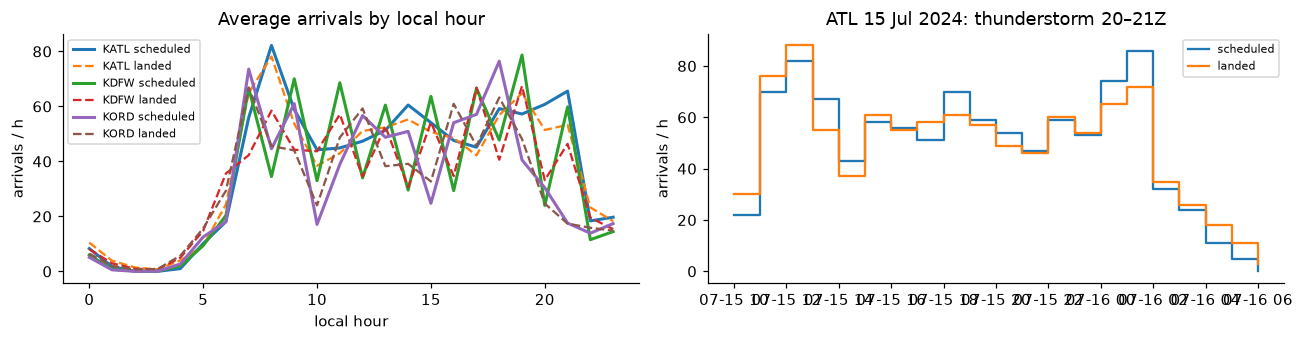

In [3]:
HOURS = pd.date_range("2023-01-01 12:00", "2025-08-01 03:00", freq="h", tz="UTC", name="hour")
panels = {a: C.hourly_panel(flights, a, HOURS) for a in AIRPORTS}
tr0, tr1 = SPLITS["train"]
nominal = {a: float(panels[a].loc[tr0:tr1, "arr_sched"].quantile(0.95)) for a in AIRPORTS}
summary = pd.DataFrame({a: {"nominal arrivals/h (p95 schedule)": nominal[a],
                            "mean arrivals/h": panels[a].arr_actual.mean(),
                            "max arrivals/h": panels[a].arr_actual.max(),
                            "dep disrupted rate": panels[a].dep_disrupted_rate.mean()} for a in AIRPORTS}).T.round(3)
display(summary)
METRICS["nominal"] = nominal

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
for a in AIRPORTS:
    p = panels[a]
    loc = p.index.tz_convert(C._AP[a]["tz"]).hour
    ax[0].plot(p.groupby(loc).arr_sched.mean(), label=f"{a} scheduled", lw=2)
    ax[0].plot(p.groupby(loc).arr_actual.mean(), ls="--", label=f"{a} landed")
ax[0].set(title="Average arrivals by local hour", xlabel="local hour", ylabel="arrivals / h"); ax[0].legend(fontsize=7)
day = panels["KATL"].loc["2024-07-15 10:00":"2024-07-16 06:00"]
ax[1].step(day.index, day.arr_sched, where="post", label="scheduled")
ax[1].step(day.index, day.arr_actual, where="post", label="landed")
ax[1].set(title="ATL 15 Jul 2024: thunderstorm 20–21Z", ylabel="arrivals / h"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 3. Weather inputs that existed at issue time

| Source | What it gives at issue time T | Notes |
|---|---|---|
| **Organisers' hourly weather** (Meteostat / NOAA ISD, ATL & DFW) | Weather observed at T (≥ 3 h before the target hour): wind resolved onto the runway, precipitation, condition codes | Official challenge file; for other airports the same Meteostat source is fetched by script |
| **METAR** (IEM ASOS) | Conditions at T: flight category, ceiling, visibility, thunderstorm, runway head/tail/crosswind | Includes special reports (SPECI), so fast changes are captured |
| **TAF** (IEM archive) | The official forecast for the target hour, from the newest TAF issued ≤ T, including TEMPO/PROB30 overlays, amendments and CB | What the TMC uses today |
| **LAMP** (IEM archive) | Statistical guidance: **lightning and convection probability**, ceiling/visibility categories, wind | Archived every 6 h, so the newest run ≤ T is used |

Runway wind components use the brief's headings (ATL 80°, DFW 180°). ORD uses its longest open runway from OurAirports (90°).

In [4]:
wxs = {a: C.load_hourly_weather(a, HEADINGS[a]) for a in AIRPORTS}   # organisers' file (ATL/DFW), Meteostat by script otherwise
print({a: wxs[a].wx_source.iloc[0] for a in AIRPORTS})
metars = {a: C.load_metar_hourly(a, HEADINGS[a]) for a in AIRPORTS}
tafs = {a: C.taf_hourly(a, HEADINGS[a]) for a in AIRPORTS}
lamps = {a: C.load_lamp(a, HEADINGS[a]) for a in AIRPORTS}
display(pd.DataFrame({a: {"METAR hours": len(metars[a]), "TAF issuances": tafs[a].product_id.nunique(),
                          "TAF hourly rows": len(tafs[a]), "LAMP runs": lamps[a].runtime.nunique(),
                          "LAMP rows": len(lamps[a])} for a in AIRPORTS}).T)

{'KATL': "organisers' hourly file", 'KDFW': "organisers' hourly file", 'KORD': 'Meteostat (fetched)'}


,METAR hours,TAF issuances,TAF hourly rows,LAMP runs,LAMP rows
KATL,22704,12365,370950,3767,94950
KDFW,22704,9142,274260,3767,94950
KORD,22704,8879,266370,3767,94950


## 4. The forecast table: one row per (airport, target hour, lead time 3–12 h)

In [5]:
t0 = time.time()
aar = pd.concat([C.build_aar_table(panels[a], metars[a], tafs[a], lamps[a], a, nominal[a], wx=wxs[a]) for a in AIRPORTS],
                ignore_index=True)
aar["split"] = "none"
for s, (lo, hi) in SPLITS.items():
    aar.loc[(aar.hour >= pd.Timestamp(lo, tz="UTC")) & (aar.hour < pd.Timestamp(hi, tz="UTC")), "split"] = s
aar["y_n"] = aar.y_arr / aar.nominal
aar["busy"] = (aar.arr_sched >= 0.4 * aar.nominal).astype(int)                  # an arrival bank, not the night
aar["wx_impacted"] = ((aar.met_cat_at_H >= 2) | (aar.met_ts_at_H == 1) | (aar.met_winter_at_H == 1)).astype(int)  # IFR/LIFR, thunderstorm or snow/ice observed
print(f"{len(aar):,} rows in {time.time() - t0:.0f}s; leakage asserts passed")
display(aar.groupby(["airport", "split"]).size().unstack())
cover = aar[aar.split != "none"].groupby("airport")[["issue", "runtime"]].apply(lambda d: d.notna().mean()).round(3)
display(cover.rename(columns={"issue": "has TAF", "runtime": "has LAMP"}))

678,720 rows in 1s; leakage asserts passed


split,none,test,train,val
airport,,,,
KATL,400,50640,131040,44160
KDFW,400,50640,131040,44160
KORD,400,50640,131040,44160


,has TAF,has LAMP
airport,,
KATL,1.0,0.973
KDFW,1.0,0.973
KORD,1.0,0.973


### How good are the forecasts we feed in?
We compare what the TAF and LAMP said 6 h ahead with what the METAR then reported. This shows why both are useful: they miss different things.

In [6]:
def skill(pred, obs):
    pred, obs = pred.astype(bool), obs.astype(bool)
    hits = (pred & obs).sum(); miss = (~pred & obs).sum(); fa = (pred & ~obs).sum()
    return {"POD (share of events forecast)": hits / max(hits + miss, 1), "FAR (false alarm ratio)": fa / max(hits + fa, 1),
            "CSI": hits / max(hits + miss + fa, 1), "events": int(obs.sum())}

t6 = aar[(aar.lead_h == 6) & (aar.split != "none") & aar.met_ts_at_H.notna()]
sk = pd.DataFrame({
    "TAF thunderstorm (incl. TEMPO/PROB)": skill(t6.taf_any_ts.fillna(0) > 0, t6.met_ts_at_H == 1),
    "LAMP lightning prob ≥ 20%": skill(t6.lamp_ltg_prob.fillna(0) >= 20, t6.met_ts_at_H == 1),
    "TAF IFR or worse": skill(t6.taf_worst_cat.fillna(0) >= 2, t6.met_cat_at_H >= 2),
    "LAMP ceiling < 1000 ft or vis < 3 mi": skill((t6.lamp_cig_cat.fillna(8) <= 3) | (t6.lamp_vis_cat.fillna(7) <= 3), t6.met_cat_at_H >= 2),
}).T.round(3)
display(sk)
METRICS["input_skill_lead6"] = sk.reset_index().to_dict(orient="records")

,POD (share of events forecast),FAR (false alarm ratio),CSI,events
TAF thunderstorm (incl. TEMPO/PROB),0.556,0.765,0.198,1127.0
LAMP lightning prob ≥ 20%,0.201,0.585,0.156,1127.0
TAF IFR or worse,0.663,0.387,0.467,5014.0
LAMP ceiling < 1000 ft or vis < 3 mi,0.657,0.363,0.478,5014.0


## ★ Main target: will this ATL/DFW flight be delayed more than 45 minutes?

* **Rows:** every flight departing from **or** arriving at ATL/DFW (full BTS data). The label is `DEP_DELAY > 45` for departures and `ARR_DELAY > 45` for arrivals.
* **Assumption (stated):** cancelled and diverted flights have no delay value, so they are excluded from this label. They are covered separately in section 6.
* **Issue time:** `T = scheduled hour − lead`, with lead 3–12 h. Training uses one random lead per flight; testing scores every flight at 3, 6 and 12 h.
* **Inputs known at T:** the schedule; aircraft rotation (the inbound aircraft's delay, only if it had already departed by T); for arrivals, the flight's own departure if it had already happened by T; airport congestion; the organisers' **hourly weather observed ≥ 3 h earlier**; and the TAF/LAMP forecasts issued by T plus Jev's reading of them.
* **Training:** ATL+DFW, Jan 2023 – Jun 2024 (a random 60% of rows to keep training fast). Validation: H2 2024 (early stopping, calibration, decision threshold). **Test: Jan–Jul 2025.**

In [7]:
t0 = time.time()
hub = C.hub_flight_rows(flights, AIRPORTS)
hub["split"] = "none"
for s_, (lo, hi) in SPLITS.items():
    hub.loc[(hub.hour >= pd.Timestamp(lo, tz="UTC")) & (hub.hour < pd.Timestamp(hi, tz="UTC")), "split"] = s_
hub = hub[hub.split != "none"]
excluded = hub.y45.isna().mean()
lab = hub[hub.y45.notna()].reset_index(drop=True)
print(f"{len(hub):,} hub flight-ends; {excluded:.1%} cancelled/diverted excluded from the label ({time.time() - t0:.0f}s)")
display(lab.groupby(["airport", "is_arrival", "split"]).y45.agg(["size", "mean"]).unstack().round(3))

rng = np.random.default_rng(1)
def mrows(d, lead=None):
    d = d.copy()
    d["lead_h"] = lead if lead is not None else rng.integers(3, 13, len(d))
    out = C.assemble_main_rows(d, aar)          # asserts: weather observed >= 3 h before the scheduled time
    num = out.select_dtypes("float64").columns
    out[num] = out[num].astype("float32")
    return out

trn = lab[(lab.split == "train") & lab.airport.isin(TRAIN_AIRPORTS)]
MTR = mrows(trn.sample(frac=0.6, random_state=1))
MVA = mrows(lab[(lab.split == "val") & lab.airport.isin(TRAIN_AIRPORTS)])
print(f"train {len(MTR):,}  val {len(MVA):,}  ({time.time() - t0:.0f}s); 3-hour weather rule asserted on every row")

4,717,496 hub flight-ends; 1.6% cancelled/diverted excluded from the label (5s)


size                   mean              
split                 test   train     val   test  train    val
airport is_arrival                                             
KATL    0           178363  499644  172037  0.122  0.083  0.089
        1           177457  498338  171612  0.103  0.077  0.084
KDFW    0           178164  428230  160284  0.147  0.127  0.120
        1           176829  425854  159636  0.137  0.114  0.103
KORD    0           177171  387797  143931  0.124  0.106  0.106
        1           176274  386014  143360  0.120  0.096  0.092

train 1,111,240  val 663,569  (7s); 3-hour weather rule asserted on every row


In [8]:
MPARAMS = dict(objective="binary", learning_rate=0.05, num_leaves=127, min_data_in_leaf=200, feature_fraction=0.8,
               bagging_fraction=0.8, bagging_freq=1, lambda_l2=5.0, verbose=-1, seed=7, max_cat_to_onehot=8, cat_smooth=20)

def fit_main(feats):
    cats = [f for f in feats if f in ("carrier", "other")]
    dtr = lgb.Dataset(MTR[feats], MTR.y45, categorical_feature=cats, free_raw_data=False)
    dva = lgb.Dataset(MVA[feats], MVA.y45, reference=dtr, categorical_feature=cats)
    return lgb.train(MPARAMS, dtr, 3000, valid_sets=[dva], callbacks=[lgb.early_stopping(100, verbose=False)])

g = C.MAIN_GROUPS
MAIN_SETS = {
    "Schedule only": g["schedule"],
    "+ ops (inbound aircraft, own departure, congestion)": g["schedule"] + g["ops"],
    "+ hourly weather file (≥ 3 h old)": g["schedule"] + g["ops"] + g["hourly_wx"],
    "+ TAF / LAMP / METAR / Jev (full model)": C.MAIN_FEATURES,
}
mains = {}
for name, feats in MAIN_SETS.items():
    t0 = time.time(); mains[name] = fit_main(feats)
    print(f"{name:52s} trees={mains[name].best_iteration:4d}  {time.time() - t0:4.0f}s")
main = mains["+ TAF / LAMP / METAR / Jev (full model)"]
miso = IsotonicRegression(out_of_bounds="clip").fit(main.predict(MVA[C.MAIN_FEATURES]), MVA.y45)

# Decision threshold chosen on validation (max F1), then frozen for test
pv = miso.predict(main.predict(MVA[C.MAIN_FEATURES]))
grid = np.linspace(0.05, 0.8, 76)
f1s = [2 * ((pv >= t) & (MVA.y45 == 1)).sum() / max((pv >= t).sum() + (MVA.y45 == 1).sum(), 1) for t in grid]
THR = float(grid[int(np.argmax(f1s))])
print(f"Decision threshold (max F1 on validation): {THR:.2f}")

mkey = ["airport", "is_arrival", "carrier", "hour_local_f", "month_local"]
mrate = lab[lab.split == "train"].groupby(mkey, observed=True).y45.agg(["sum", "count"])
mprior = lab[lab.split == "train"].y45.mean()
MCLIM = ((mrate["sum"] + 20 * mprior) / (mrate["count"] + 20)).rename("p_clim").reset_index()

def main_metrics(y, p, thr):
    y = np.asarray(y).astype(int); a = p >= thr
    tp, fp, fn = (a & (y == 1)).sum(), (a & (y == 0)).sum(), (~a & (y == 1)).sum()
    prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return {"base rate": y.mean(), "accuracy": (a == y).mean(), "precision": prec, "recall": rec,
            "F1": 2 * prec * rec / max(prec + rec, 1e-9), "PR-AUC": average_precision_score(y, p),
            "ROC-AUC": roc_auc_score(y, p), "Brier": brier_score_loss(y, p), "flagged share": a.mean()}

Schedule only                                        trees=  72     6s


+ ops (inbound aircraft, own departure, congestion)  trees= 260    14s


+ hourly weather file (≥ 3 h old)                    trees= 277    16s


+ TAF / LAMP / METAR / Jev (full model)              trees= 230    21s


Decision threshold (max F1 on validation): 0.19


In [9]:
# Score the 2025 test set at 3, 6 and 12 h; keep only what's needed so memory stays small
res, keep6 = {}, None
prov = pd.read_parquet("data/processed/flights_clean_hubs.parquet")
pkey = ["FL_DATE", "OP_UNIQUE_CARRIER", "OP_CARRIER_FL_NUM", "ORIGIN", "DEST", "CRS_DEP_TIME"]
pk = set(map(tuple, prov[pkey].astype(str).values))
for k in (3, 6, 12):
    d = mrows(lab[lab.split == "test"], lead=k)
    d = d.merge(MCLIM, on=mkey, how="left"); d["p_clim"] = d.p_clim.fillna(mprior)
    d["p"] = miso.predict(main.predict(d[C.MAIN_FEATURES]))
    for nm, feats in MAIN_SETS.items():
        if nm != "+ TAF / LAMP / METAR / Jev (full model)":
            d[f"p_{nm}"] = mains[nm].predict(d[feats])
    k_ = d[pkey].astype({"OP_CARRIER_FL_NUM": "Int64", "CRS_DEP_TIME": "Int64"}).astype(str)
    d["in_provided_sample"] = [tuple(r) in pk for r in k_.values]
    for scope, sub in {"ATL+DFW": d[d.airport.isin(TRAIN_AIRPORTS)], "ATL+DFW (organisers' sample rows)": d[d.airport.isin(TRAIN_AIRPORTS) & d.in_provided_sample],
                       "ORD (unseen)": d[d.airport == "KORD"]}.items():
        if sub.empty:
            continue
        y = sub.y45.values
        res[(k, scope, "Always 'on time'")] = main_metrics(y, np.zeros(len(y)), 0.5)
        res[(k, scope, "Historical rate")] = main_metrics(y, sub.p_clim.values, THR)
        for nm in MAIN_SETS:
            if nm == "+ TAF / LAMP / METAR / Jev (full model)":
                res[(k, scope, nm)] = main_metrics(y, sub.p.values, THR)
            else:   # uncalibrated ablation models: compare at the same alert rate as the full model
                q = np.quantile(sub[f"p_{nm}"], 1 - (sub.p >= THR).mean())
                res[(k, scope, nm)] = main_metrics(y, sub[f"p_{nm}"].values, q)
    if k == 6:
        keep6 = d[["airport", "is_arrival", "y45", "p", "in_provided_sample", "hour", "met_cat_at_H", "met_ts_at_H"]].copy()
    del d
mt = pd.DataFrame(res).T.round(3); mt.index.names = ["lead_h", "scope", "model"]
display(mt.loc[6])
METRICS["main_test"] = mt.reset_index().to_dict(orient="records")
METRICS["main_threshold"] = THR
METRICS["main_excluded_cancelled_diverted"] = float(excluded)
by = keep6[keep6.airport.isin(TRAIN_AIRPORTS)].groupby(["airport", "is_arrival"]).apply(
    lambda s_: pd.Series(main_metrics(s_.y45.values, s_.p.values, THR)), include_groups=False).round(3)
by.index = [f"{a} {'arrivals' if r else 'departures'}" for a, r in by.index]
display(by)
METRICS["main_by_airport_direction"] = by.reset_index().to_dict(orient="records")
wxsplit = keep6[keep6.airport.isin(TRAIN_AIRPORTS)].groupby((keep6.met_cat_at_H >= 2) | (keep6.met_ts_at_H == 1)).apply(
    lambda s_: pd.Series(main_metrics(s_.y45.values, s_.p.values, THR)), include_groups=False).round(3)
wxsplit.index = ["fair weather at scheduled hour", "IFR / thunderstorm at scheduled hour"][:len(wxsplit)]
display(wxsplit)
METRICS["main_by_weather"] = wxsplit.reset_index().to_dict(orient="records")
cal = keep6[keep6.airport.isin(TRAIN_AIRPORTS)].assign(bin=lambda x: pd.cut(x.p, [0, .05, .1, .2, .3, .4, .5, .6, .8, 1], include_lowest=True))
mcal = cal.groupby("bin", observed=True).agg(predicted=("p", "mean"), observed=("y45", "mean"), flights=("p", "size"))
METRICS["main_calibration_lead6"] = mcal.reset_index(drop=True).round(4).to_dict(orient="records")
mg = pd.Series(main.feature_importance("gain"), index=C.MAIN_FEATURES)
mgrp = {f: gname for gname, fs in C.MAIN_GROUPS.items() for f in fs}
METRICS["main_importance_groups"] = (mg.groupby(mgrp).sum() / mg.sum()).round(3).to_dict()
METRICS["main_importance_top"] = {C.label(k_): round(v, 4) for k_, v in (mg / mg.sum()).sort_values(ascending=False).head(15).items()}
display(pd.Series(METRICS["main_importance_groups"]).to_frame("share of gain"))

/var/folders/67/sd_f331s74v9ydx_p2f1tj3h0000gn/T/ipykernel_79750/1762986414.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d["p"] = miso.predict(main.predict(d[C.MAIN_FEATURES]))


/var/folders/67/sd_f331s74v9ydx_p2f1tj3h0000gn/T/ipykernel_79750/1762986414.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d[f"p_{nm}"] = mains[nm].predict(d[feats])


/var/folders/67/sd_f331s74v9ydx_p2f1tj3h0000gn/T/ipykernel_79750/1762986414.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d[f"p_{nm}"] = mains[nm].predict(d[feats])


/var/folders/67/sd_f331s74v9ydx_p2f1tj3h0000gn/T/ipykernel_79750/1762986414.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d[f"p_{nm}"] = mains[nm].predict(d[feats])


/var/folders/67/sd_f331s74v9ydx_p2f1tj3h0000gn/T/ipykernel_79750/1762986414.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d["in_provided_sample"] = [tuple(r) in pk for r in k_.values]


...

/var/folders/67/sd_f331s74v9ydx_p2f1tj3h0000gn/T/ipykernel_79750/1762986414.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d["in_provided_sample"] = [tuple(r) in pk for r in k_.values]


base rate  accuracy  precision  recall     F1  PR-AUC  ROC-AUC  Brier  flagged share
scope                             model                                                                                                                                   
ATL+DFW                           Always 'on time'                                        0.127     0.873      0.000   0.000  0.000   0.127    0.500  0.127          0.000
                                  Historical rate                                         0.127     0.808      0.247   0.249  0.248   0.211    0.647  0.108          0.128
                                  Schedule only                                           0.127     0.763      0.251   0.436  0.319   0.268    0.686  0.104          0.221
                                  + ops (inbound aircraft, own departure, congest...      0.127     0.780      0.289   0.501  0.366   0.327    0.731  0.100          0.221
                                  + hourly weather file (≥ 3 h old)                       0.127     0.783      0.296   0.513  0.375   0.334    0.744  0.099          0.221
                                  + TAF / LAMP / METAR / Jev (full model)                 0.127     0.790      0.313   0.543  0.397   0.351    0.761  0.097          0.221
ATL+DFW (organisers' sample rows) Always 'on time'                                        0.132     0.868      0.000   0.000  0.000   0.132    0.500  0.132          0.000
                                  Historical rate                                         0.132     0.805      0.263   0.267  0.265   0.222    0.639  0.111          0.134
                                  Schedule only                                           0.132     0.753      0.252   0.447  0.322   0.292    0.692  0.106          0.233
                                  + ops (inbound aircraft, own departure, congest...      0.132     0.768      0.285   0.505  0.365   0.339    0.730  0.102          0.233
                                  + hourly weather file (≥ 3 h old)                       0.132     0.771      0.291   0.516  0.372   0.344    0.738  0.102          0.233
                                  + TAF / LAMP / METAR / Jev (full model)                 0.132     0.776      0.302   0.536  0.387   0.354    0.752  0.100          0.233
ORD (unseen)                      Always 'on time'                                        0.122     0.878      0.000   0.000  0.000   0.122    0.500  0.122          0.000
                                  Historical rate                                         0.122     0.821      0.251   0.233  0.242   0.203    0.643  0.104          0.113
                                  Schedule only                                           0.122     0.726      0.222   0.498  0.307   0.243    0.678  0.102          0.274
                                  + ops (inbound aircraft, own departure, congest...      0.122     0.739      0.247   0.554  0.342   0.283    0.717  0.099          0.274
                                  + hourly weather file (≥ 3 h old)                       0.122     0.742      0.251   0.563  0.348   0.299    0.728  0.098          0.274
                                  + TAF / LAMP / METAR / Jev (full model)                 0.122     0.744      0.256   0.574  0.354   0.311    0.735  0.098          0.274

,base rate,accuracy,precision,recall,F1,PR-AUC,ROC-AUC,Brier,flagged share
KATL departures,0.122,0.816,0.332,0.504,0.400,0.355,0.775,0.093,0.185
KATL arrivals,0.103,0.832,0.287,0.427,0.343,0.272,0.739,0.084,0.153
KDFW departures,0.147,0.743,0.321,0.667,0.433,0.405,0.782,0.106,0.306
KDFW arrivals,0.137,0.771,0.306,0.532,0.388,0.350,0.734,0.105,0.238


,base rate,accuracy,precision,recall,F1,PR-AUC,ROC-AUC,Brier,flagged share
fair weather at scheduled hour,0.119,0.794,0.296,0.529,0.380,0.330,0.757,0.093,0.213
IFR / thunderstorm at scheduled hour,0.210,0.752,0.438,0.625,0.515,0.494,0.775,0.139,0.300


,share of gain
forecasts,0.298
hourly_wx,0.066
ops,0.103
schedule,0.533


## 5. Bonus: arrival-capacity model (AAR)

### 5a. Baselines (what the model has to beat)
1. **Schedule:** "everything lands as scheduled". This is the plan with no weather knowledge.
2. **Climatology:** average landings for this airport, local hour and weekday (training period).
3. **Persistence:** schedule × the landed/scheduled ratio at issue time. This is roughly how a reactive TMC thinks.
4. **TAF rule:** schedule × a typical reduction factor for the TAF's worst category (VFR/MVFR/IFR/LIFR/thunderstorm), learned from training data. This is a rules-based TAF lookup, the standard operational benchmark.

In [10]:
def taf_class(d):
    c = d.taf_worst_cat.fillna(0).map({0: "VFR", 1: "MVFR", 2: "IFR", 3: "LIFR"})
    return c.where(d.taf_any_ts.fillna(0) == 0, "TS")

aar["taf_class"] = taf_class(aar)
tr = aar[(aar.split == "train") & aar.airport.isin(TRAIN_AIRPORTS)]
busy_tr = tr[tr.arr_sched >= 10]
TAF_FACTORS = (busy_tr.y_arr / busy_tr.arr_sched).groupby(busy_tr.taf_class).median().to_dict()
print("TAF rule factors:", {k: round(v, 3) for k, v in TAF_FACTORS.items()})

clim = (aar[aar.split == "train"].groupby(["airport", "hour_local", "dow"]).y_arr.mean().rename("b_clim").reset_index())
aar = aar.drop(columns=["b_clim"], errors="ignore").merge(clim, on=["airport", "hour_local", "dow"], how="left")
aar["b_sched"] = aar.arr_sched.astype(float)
aar["b_persist"] = aar.arr_sched * aar.rt_ratio.fillna(1).clip(0, 1.3)
aar["b_taf"] = aar.arr_sched * aar.taf_class.map(TAF_FACTORS).fillna(1)
BASELINES = {"b_sched": "Schedule", "b_clim": "Climatology", "b_persist": "Persistence", "b_taf": "TAF rule"}

TAF rule factors: {'IFR': 0.988, 'LIFR': 1.013, 'MVFR': 0.98, 'TS': 0.9, 'VFR': 0.975}


/var/folders/67/sd_f331s74v9ydx_p2f1tj3h0000gn/T/ipykernel_79750/3437919088.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  aar["b_sched"] = aar.arr_sched.astype(float)
/var/folders/67/sd_f331s74v9ydx_p2f1tj3h0000gn/T/ipykernel_79750/3437919088.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  aar["b_persist"] = aar.arr_sched * aar.rt_ratio.fillna(1).clip(0, 1.3)
/var/folders/67/sd_f331s74v9ydx_p2f1tj3h0000gn/T/ipykernel_79750/3437919088.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the resu

### 5b. LightGBM with an ablation by data source
We add data sources one at a time. If a source doesn't lower test RMSE, it doesn't earn a place in the model.

The last step adds **Jev** (TypeSafe's System One classifier). Jev reads each TAF group, decoded to plain English, and returns typed answers: hazard type probabilities and an arrival-impact severity score. These are cached in `data/jev/taf_readings.parquet` by `scripts/jev_read_tafs.py`. Jev only *reads text*; LightGBM does all the arithmetic.

In [11]:
PARAMS = dict(objective="regression", learning_rate=0.03, num_leaves=63, min_data_in_leaf=40, feature_fraction=0.8,
              bagging_fraction=0.8, bagging_freq=1, lambda_l2=2.0, verbose=-1, seed=7)

def fit(feats, train, val, params=PARAMS, target="y_n"):
    dtr = lgb.Dataset(train[feats], train[target], free_raw_data=False)
    dva = lgb.Dataset(val[feats], val[target], reference=dtr)
    return lgb.train(params, dtr, 4000, valid_sets=[dva], callbacks=[lgb.early_stopping(150, verbose=False)])

def rmse(p, y):
    return float(np.sqrt(np.mean((np.asarray(p) - np.asarray(y)) ** 2)))

TR = aar[(aar.split == "train") & aar.airport.isin(TRAIN_AIRPORTS)]
VA = aar[(aar.split == "val") & aar.airport.isin(TRAIN_AIRPORTS)]
TE = aar[(aar.split == "test") & aar.airport.isin(TRAIN_AIRPORTS)].copy()

ABLATION = {
    "Schedule only": FEATURE_GROUPS["schedule"],
    "+ real-time ops": FEATURE_GROUPS["schedule"] + FEATURE_GROUPS["realtime"],
    "+ hourly weather (≥3 h old)": FEATURE_GROUPS["schedule"] + FEATURE_GROUPS["realtime"] + FEATURE_GROUPS["wx"],
    "+ METAR at issue": FEATURE_GROUPS["schedule"] + FEATURE_GROUPS["realtime"] + FEATURE_GROUPS["wx"] + FEATURE_GROUPS["metar"],
    "+ TAF": FEATURE_GROUPS["schedule"] + FEATURE_GROUPS["realtime"] + FEATURE_GROUPS["wx"] + FEATURE_GROUPS["metar"] + FEATURE_GROUPS["taf"],
    "+ LAMP": FEATURE_GROUPS["schedule"] + FEATURE_GROUPS["realtime"] + FEATURE_GROUPS["wx"] + FEATURE_GROUPS["metar"] + FEATURE_GROUPS["taf"] + FEATURE_GROUPS["lamp"],
}
if "jev" in FEATURE_GROUPS:
    ABLATION["+ Jev reads the TAF (full model)"] = AAR_FEATURES
else:
    ABLATION["+ LAMP (full model)"] = ABLATION.pop("+ LAMP")
FULL = list(ABLATION)[-1]
models = {}
for name, feats in ABLATION.items():
    t0 = time.time()
    models[name] = fit(feats, TR, VA)
    TE[f"p_{name}"] = models[name].predict(TE[feats]) * TE.nominal
    print(f"{name:22s} trees={models[name].best_iteration:4d}  {time.time() - t0:4.0f}s")
aar_model = models[FULL]
TE["pred"] = TE[f"p_{FULL}"]

def score_table(d, cols):
    subsets = {"all hours": d, "busy hours": d[d.busy == 1], "weather-impacted hours": d[d.wx_impacted == 1],
               "busy & weather-impacted": d[(d.busy == 1) & (d.wx_impacted == 1)]}
    return pd.DataFrame({s: {lab: rmse(x[c], x.y_arr) for c, lab in cols.items()} for s, x in subsets.items()}).round(2)

cols = {**BASELINES, **{f"p_{n}": n for n in ABLATION}}
rmse_tab = score_table(TE, cols)
display(rmse_tab.style.highlight_min(axis=0, color="#cfe8cf").format("{:.2f}"))
METRICS["aar_rmse_test"] = rmse_tab.reset_index().rename(columns={"index": "model"}).to_dict(orient="records")
METRICS["aar_rows"] = {"weather_impacted_test_hours": int(TE[TE.lead_h == 3].wx_impacted.sum()),
                       "test_hours": int((TE.lead_h == 3).sum())}

Schedule only          trees= 349     5s


+ real-time ops        trees= 345     6s


+ hourly weather (≥3 h old) trees= 929    12s


+ METAR at issue       trees=1083    14s


+ TAF                  trees=1359    18s


+ LAMP                 trees=1346    19s


+ Jev reads the TAF (full model) trees=1175    17s


,all hours,busy hours,weather-impacted hours,busy & weather-impacted
Schedule,12.23,14.61,18.05,22.13
Climatology,10.48,12.12,15.52,18.69
Persistence,15.87,19.48,19.68,24.16
TAF rule,11.82,13.94,17.08,20.77
Schedule only,9.24,11.14,15.16,18.39
+ real-time ops,8.97,10.90,14.66,17.77
+ hourly weather (≥3 h old),8.84,10.77,14.26,17.22
+ METAR at issue,8.82,10.74,14.20,17.11
+ TAF,8.49,10.33,13.21,15.79
+ LAMP,8.35,10.13,13.00,15.46


### 5c. Error by lead time (the 3–12 h window)

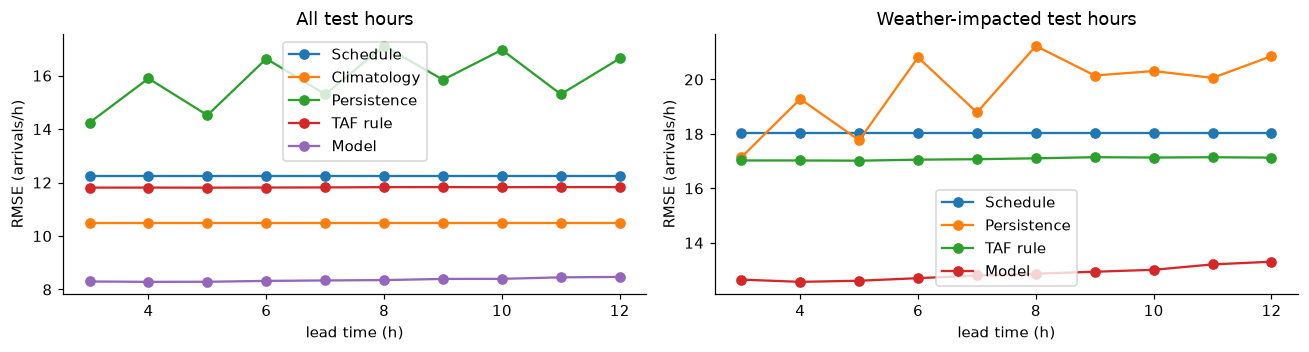

lead_h,3,4,5,6,7,8,9,10,11,12
Schedule,12.23,12.23,12.23,12.23,12.23,12.23,12.23,12.23,12.23,12.23
Climatology,10.48,10.48,10.48,10.48,10.48,10.48,10.48,10.48,10.48,10.48
Persistence,14.24,15.89,14.52,16.63,15.30,17.11,15.84,16.96,15.30,16.64
TAF rule,11.81,11.81,11.81,11.81,11.82,11.83,11.83,11.83,11.83,11.83
Model,8.30,8.29,8.29,8.32,8.34,8.35,8.39,8.40,8.45,8.47


In [12]:
by_lead = (TE.groupby("lead_h").apply(lambda d: pd.Series({lab: rmse(d[c], d.y_arr) for c, lab in
          {"b_sched": "Schedule", "b_clim": "Climatology", "b_persist": "Persistence", "b_taf": "TAF rule", "pred": "Model"}.items()}),
          include_groups=False))
by_lead_imp = (TE[TE.wx_impacted == 1].groupby("lead_h").apply(lambda d: pd.Series({lab: rmse(d[c], d.y_arr) for c, lab in
          {"b_sched": "Schedule", "b_persist": "Persistence", "b_taf": "TAF rule", "pred": "Model"}.items()}), include_groups=False))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.3), sharey=False)
by_lead.plot(ax=ax[0], marker="o", title="All test hours"); by_lead_imp.plot(ax=ax[1], marker="o", title="Weather-impacted test hours")
for x in ax: x.set(xlabel="lead time (h)", ylabel="RMSE (arrivals/h)")
plt.tight_layout(); plt.show()
display(by_lead.round(2).T)
METRICS["aar_rmse_by_lead"] = by_lead.round(3).reset_index().to_dict(orient="records")
METRICS["aar_rmse_by_lead_impacted"] = by_lead_imp.round(3).reset_index().to_dict(orient="records")

### 5d. Uncertainty: conformalized quantile bands (80%)
Quantile models (P10/P90) are widened just enough that, on the validation period, 80% of real outcomes fall inside the band. This is split-conformal with a separate correction per group of lead time × busy schedule × forecast weather signal ("Mondrian" conformal), all of which are known at issue time. We then **check coverage on the test period**, including in bad weather, where it is hardest.

In [13]:
q_models = {}
for q in (0.1, 0.9):
    q_models[q] = fit(AAR_FEATURES, TR, VA, params={**PARAMS, "objective": "quantile", "alpha": q})
ALPHA = 0.2
va = VA.copy()
va["lo"], va["hi"] = q_models[0.1].predict(va[AAR_FEATURES]), q_models[0.9].predict(va[AAR_FEATURES])
va["score"] = np.maximum(va.lo - va.y_n, va.y_n - va.hi)

def conf_group(d):
    # Mondrian groups, all known at issue time: lead time x busy schedule x forecast weather signal
    sig = ((d.taf_any_ts.fillna(0) > 0) | (d.taf_worst_cat.fillna(0) >= 2) | (d.lamp_ltg_prob.fillna(0) >= 20)).astype(int)
    return d.lead_h.astype(int).astype(str) + "|" + d.busy.astype(str) + "|" + sig.astype(str)

va["grp"] = conf_group(va)
CONFORMAL = {k: float(np.quantile(g.score, min(1, (1 - ALPHA) * (1 + 1 / len(g))))) for k, g in va.groupby("grp")}

def bands(d):
    off = conf_group(d).map(CONFORMAL).fillna(max(CONFORMAL.values())).values
    lo = q_models[0.1].predict(d[AAR_FEATURES]) - off
    hi = q_models[0.9].predict(d[AAR_FEATURES]) + off
    return np.clip(lo, 0, None) * d.nominal.values, np.clip(hi, 0, None) * d.nominal.values

TE["lo"], TE["hi"] = bands(TE)
TE["covered"] = (TE.y_arr >= TE.lo) & (TE.y_arr <= TE.hi)
cov = pd.DataFrame({"coverage (target 80%)": [TE.covered.mean(), TE[TE.busy == 1].covered.mean(), TE[TE.wx_impacted == 1].covered.mean()],
                    "mean band width (arrivals/h)": [(TE.hi - TE.lo).mean(), (TE.hi - TE.lo)[TE.busy == 1].mean(), (TE.hi - TE.lo)[TE.wx_impacted == 1].mean()]},
                   index=["all test hours", "busy hours", "weather-impacted hours"]).round(3)
display(cov)
METRICS["aar_coverage"] = cov.reset_index().to_dict(orient="records")

,coverage (target 80%),mean band width (arrivals/h)
all test hours,0.781,15.857
busy hours,0.770,21.094
weather-impacted hours,0.731,20.018


### 5e. Detecting capacity reductions
A **capacity-reduction hour** is a busy hour where landings fell more than 20% below schedule. An **alert** fires when the forecast is more than 15% below schedule. This is how the dashboard decides to raise a warning.

In [14]:
ALERT_RATIO = 0.85
def detect(d, method):
    busy = d[d.busy == 1]
    event = busy.y_arr < 0.8 * busy.arr_sched
    alert = {"Model": busy.pred < ALERT_RATIO * busy.arr_sched,
             "TAF says TS or IFR": (busy.taf_any_ts.fillna(0) > 0) | (busy.taf_worst_cat.fillna(0) >= 2),
             "Persistence": busy.b_persist < ALERT_RATIO * busy.arr_sched}[method]
    return skill(alert, event)
det = pd.concat({k: pd.DataFrame({m: detect(TE[TE.lead_h == k], m) for m in
                 ["Model", "TAF says TS or IFR", "Persistence"]}).T for k in (3, 6, 9, 12)})
display(det.round(3))
METRICS["aar_detection"] = det.round(4).reset_index().rename(columns={"level_0": "lead_h", "level_1": "method"}).to_dict(orient="records")

POD (share of events forecast)  FAR (false alarm ratio)    CSI  events
3  Model                                        0.601                    0.413  0.423  1430.0
   TAF says TS or IFR                           0.181                    0.672  0.132  1430.0
   Persistence                                  0.283                    0.705  0.169  1430.0
6  Model                                        0.586                    0.414  0.414  1430.0
   TAF says TS or IFR                           0.197                    0.666  0.141  1430.0
   Persistence                                  0.187                    0.714  0.128  1430.0
9  Model                                        0.580                    0.427  0.405  1430.0
   TAF says TS or IFR                           0.191                    0.680  0.136  1430.0
   Persistence                                  0.360                    0.643  0.218  1430.0
12 Model                                        0.576                    0.429  0.402  1430.0
   TAF says TS or IFR                           0.188                    0.677  0.135  1430.0
   Persistence                                  0.289                    0.668  0.183  1430.0

### 5f. Does it generalise? (the "any airport" test)
* **ORD (never seen in training):** the model trained on ATL+DFW is applied with ORD's own runway heading and nominal rate. No ORD outcomes are used.
* **Leave one airport out:** train on ATL only and test on DFW, then the reverse.

In [15]:
def eval_airport(model, d):
    d = d.copy(); d["pred"] = model.predict(d[AAR_FEATURES]) * d.nominal
    return {"Model": rmse(d.pred, d.y_arr), "Schedule": rmse(d.b_sched, d.y_arr), "Climatology": rmse(d.b_clim, d.y_arr),
            "Persistence": rmse(d.b_persist, d.y_arr), "TAF rule": rmse(d.b_taf, d.y_arr),
            "Model (weather-impacted)": rmse(d.pred[d.wx_impacted == 1], d.y_arr[d.wx_impacted == 1]),
            "TAF rule (weather-impacted)": rmse(d.b_taf[d.wx_impacted == 1], d.y_arr[d.wx_impacted == 1])}

ORD_TE = aar[(aar.split == "test") & (aar.airport == "KORD")]
gen = {"KORD (unseen, trained on ATL+DFW)": eval_airport(aar_model, ORD_TE)}
for held in TRAIN_AIRPORTS:
    other = [a for a in TRAIN_AIRPORTS if a != held]
    m = fit(AAR_FEATURES, aar[(aar.split == "train") & aar.airport.isin(other)], aar[(aar.split == "val") & aar.airport.isin(other)])
    gen[f"{held} (trained on {other[0]} only)"] = eval_airport(m, aar[(aar.split == "test") & (aar.airport == held)])
gen = pd.DataFrame(gen).T.round(2)
display(gen)
METRICS["aar_generalisation"] = gen.reset_index().rename(columns={"index": "test"}).to_dict(orient="records")

,Model,Schedule,Climatology,Persistence,TAF rule,Model (weather-impacted),TAF rule (weather-impacted)
"KORD (unseen, trained on ATL+DFW)",7.89,11.05,11.26,15.11,10.66,10.65,14.19
KATL (trained on KDFW only),8.92,8.76,9.27,11.84,8.46,11.29,13.16
KDFW (trained on KATL only),11.78,14.91,11.56,19.07,14.42,17.80,20.82


### 5g. What drives the forecast

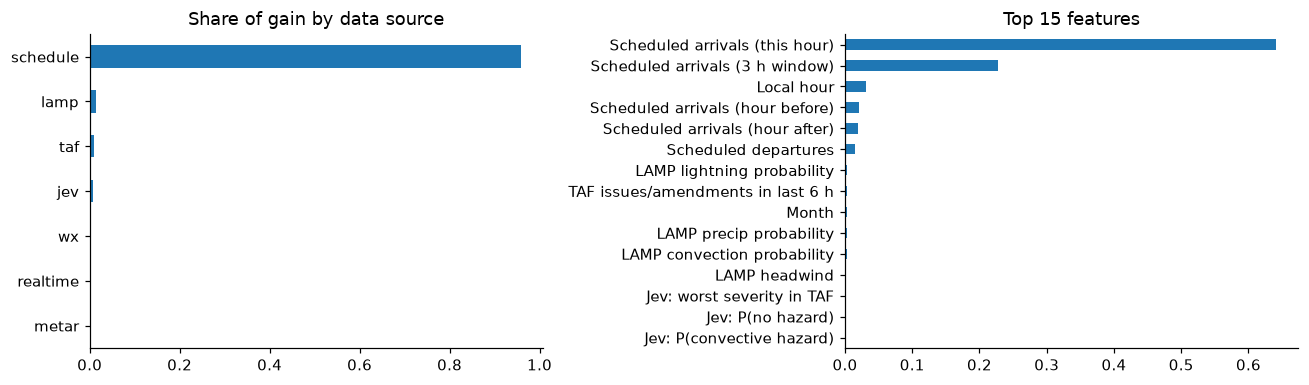

In [16]:
gain = pd.Series(aar_model.feature_importance("gain"), index=AAR_FEATURES)
grp = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}
by_group = (gain.groupby(grp).sum() / gain.sum()).sort_values(ascending=False).round(3)
top = (gain / gain.sum()).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
by_group.plot.barh(ax=ax[0], title="Share of gain by data source"); ax[0].invert_yaxis()
top.rename(index=C.label).plot.barh(ax=ax[1], title="Top 15 features"); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()
METRICS["aar_importance_groups"] = by_group.to_dict()
METRICS["aar_importance_top"] = {C.label(k): round(v, 4) for k, v in top.items()}

## 6. Supplementary: departures including cancellations (used for the storm-day views)

One row per departure from a hub. For training, each flight gets one random lead time (3–12 h). For testing, every flight is scored at 3, 6 and 12 h. Inputs:
- **Flight:** airline, destination, hour, block time.
- **Aircraft rotation:** where the inbound aircraft is. If it has already departed by the issue time, its delay and the remaining turn slack are known. Otherwise they are unknown. This is the strongest legitimate early signal for delay propagation.
- **Airport-hour forecast features:** the same TAF/LAMP/METAR/real-time inputs as above, for the departure hour.

Delay rates are reported per flight. This addresses the brief's warning about comparing raw delay minutes between big and small airports.

In [17]:
t0 = time.time()
dep = C.departures_with_inbound(flights, AIRPORTS)
dep["split"] = "none"
for s, (lo, hi) in SPLITS.items():
    dep.loc[(dep.hour >= pd.Timestamp(lo, tz="UTC")) & (dep.hour < pd.Timestamp(hi, tz="UTC")), "split"] = s
dep = dep[dep.split != "none"]
rng = np.random.default_rng(42)
dep["lead_h"] = rng.integers(3, 13, len(dep))
print(f"{len(dep):,} departures; inbound aircraft found for {dep.in_sched_arr.notna().mean():.1%}; {time.time() - t0:.0f}s")
display(dep.groupby(["airport", "split"]).disrupted_45.agg(["size", "mean"]).unstack().round(3))

def rows(d, lead=None):
    d = d.copy()
    if lead is not None:
        d["lead_h"] = lead
    out = C.assemble_flight_rows(d, aar)
    num = out.select_dtypes("float64").columns
    out[num] = out[num].astype("float32")
    return out

FTR = rows(dep[(dep.split == "train") & dep.airport.isin(TRAIN_AIRPORTS)])
FVA = rows(dep[(dep.split == "val") & dep.airport.isin(TRAIN_AIRPORTS)])
FTE = {k: rows(dep[(dep.split == "test")], lead=k) for k in (3, 6, 12)}
print(f"train {len(FTR):,}  val {len(FVA):,}  test {len(FTE[3]):,} per lead  ({time.time() - t0:.0f}s)")

2,358,885 departures; inbound aircraft found for 89.7%; 3s


size                   mean              
split      test   train     val   test  train    val
airport                                             
KATL     181076  503000  174657  0.138  0.091  0.105
KDFW     184062  436161  162175  0.178  0.146  0.132
KORD     179389  393163  145202  0.138  0.120  0.116

train 939,161  val 336,832  test 544,527 per lead  (5s)


In [18]:
CPARAMS = dict(objective="binary", learning_rate=0.05, num_leaves=127, min_data_in_leaf=200, feature_fraction=0.8,
               bagging_fraction=0.8, bagging_freq=1, lambda_l2=5.0, verbose=-1, seed=7, max_cat_to_onehot=8,
               cat_smooth=20)

def fit_clf(feats):
    cats = [f for f in feats if f in ("carrier", "dest")]
    dtr = lgb.Dataset(FTR[feats], FTR.disrupted_45, categorical_feature=cats, free_raw_data=False)
    dva = lgb.Dataset(FVA[feats], FVA.disrupted_45, reference=dtr, categorical_feature=cats)
    return lgb.train(CPARAMS, dtr, 3000, valid_sets=[dva], callbacks=[lgb.early_stopping(100, verbose=False)])

CLF_SETS = {
    "Schedule only": CLF_GROUPS["schedule"],
    "+ ops & aircraft rotation": CLF_GROUPS["schedule"] + CLF_GROUPS["ops"],
    "+ weather (full model)": CLF_FEATURES,
}
clfs = {}
for name, feats in CLF_SETS.items():
    t0 = time.time(); clfs[name] = fit_clf(feats)
    print(f"{name:28s} trees={clfs[name].best_iteration:4d}  {time.time() - t0:4.0f}s")
clf = clfs["+ weather (full model)"]

# Calibrate on validation so a "30%" really means about 30%
iso = IsotonicRegression(out_of_bounds="clip").fit(clf.predict(FVA[CLF_FEATURES]), FVA.disrupted_45)

# Baseline: historical rate for airport x airline x hour x month (training period)
key = ["airport", "carrier", "dep_hour_local", "month_local"]
hist_dep = dep[dep.split == "train"]          # each airport's own history (ORD's too: it's a baseline, not the model)
rate = hist_dep.groupby(key, observed=True).disrupted_45.agg(["sum", "count"])
prior = hist_dep.disrupted_45.mean()
CLIM = ((rate["sum"] + 20 * prior) / (rate["count"] + 20)).rename("p_clim").reset_index()

Schedule only                trees=  62     5s


+ ops & aircraft rotation    trees= 226    11s


+ weather (full model)       trees= 211    15s


In [19]:
def clf_metrics(y, p, budget=0.10):
    thr = np.quantile(p, 1 - budget)
    alert = p >= thr
    tp = (alert & (y == 1)).sum()
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "Brier": brier_score_loss(y, p),
            "precision@10% alerts": tp / max(alert.sum(), 1), "recall@10% alerts": tp / max((y == 1).sum(), 1)}

res = {}
for k, d in FTE.items():
    d = d.merge(CLIM, on=key, how="left"); d["p_clim"] = d.p_clim.fillna(prior)
    for ap_set, sub in {"ATL+DFW": d[d.airport.isin(TRAIN_AIRPORTS)], "ORD (unseen)": d[d.airport == "KORD"]}.items():
        y = sub.disrupted_45.values
        res[(k, ap_set, "Climatology")] = clf_metrics(y, sub.p_clim.values)
        for name, feats in CLF_SETS.items():
            p = clfs[name].predict(sub[feats])
            if name == "+ weather (full model)":
                p = iso.predict(p)
            res[(k, ap_set, name)] = clf_metrics(y, p)
clf_tab = pd.DataFrame(res).T.round(3)
clf_tab.index.names = ["lead_h", "airports", "model"]
display(clf_tab)
print("Base rate (test, ATL+DFW):", round(FTE[3][FTE[3].airport.isin(TRAIN_AIRPORTS)].disrupted_45.mean(), 3))

# The brief's exact label: departure delay > 45 min (flights that departed). Same model, scored on the strict label.
strict = {}
for k, d in FTE.items():
    s_ = d[d.airport.isin(TRAIN_AIRPORTS) & d.DEP_DELAY.notna()]
    strict[k] = {**clf_metrics((s_.DEP_DELAY > 45).astype(int).values, iso.predict(clf.predict(s_[CLF_FEATURES]))),
                 "base rate": float((s_.DEP_DELAY > 45).mean())}
strict = pd.DataFrame(strict).T.round(3)
strict.index.name = "lead_h"
print("Strict label: departure delay > 45 min (departed flights only)")
display(strict)
METRICS["clf_strict_dep45"] = strict.reset_index().to_dict(orient="records")
METRICS["clf_test"] = clf_tab.reset_index().to_dict(orient="records")
METRICS["clf_base_rate_test"] = float(FTE[3][FTE[3].airport.isin(TRAIN_AIRPORTS)].disrupted_45.mean())

ROC-AUC  PR-AUC  Brier  precision@10% alerts  recall@10% alerts
lead_h airports     model                                                                                     
3      ATL+DFW      Climatology                  0.645   0.249  0.129                 0.301              0.195
                    Schedule only                0.719   0.362  0.120                 0.434              0.275
                    + ops & aircraft rotation    0.799   0.493  0.106                 0.567              0.359
                    + weather (full model)       0.813   0.497  0.103                 0.544              0.418
       ORD (unseen) Climatology                  0.634   0.220  0.115                 0.278              0.203
                    Schedule only                0.706   0.294  0.111                 0.347              0.252
                    + ops & aircraft rotation    0.783   0.408  0.101                 0.480              0.348
                    + weather (full model)       0.786   0.395  0.107                 0.461              0.341
6      ATL+DFW      Climatology                  0.645   0.249  0.129                 0.301              0.195
                    Schedule only                0.719   0.362  0.120                 0.434              0.275
                    + ops & aircraft rotation    0.763   0.425  0.113                 0.502              0.318
                    + weather (full model)       0.793   0.453  0.108                 0.517              0.371
       ORD (unseen) Climatology                  0.634   0.220  0.115                 0.278              0.203
                    Schedule only                0.706   0.294  0.111                 0.347              0.252
                    + ops & aircraft rotation    0.735   0.329  0.109                 0.391              0.283
                    + weather (full model)       0.753   0.340  0.115                 0.401              0.294
12     ATL+DFW      Climatology                  0.645   0.249  0.129                 0.301              0.195
                    Schedule only                0.718   0.362  0.120                 0.434              0.275
                    + ops & aircraft rotation    0.740   0.383  0.117                 0.460              0.291
                    + weather (full model)       0.781   0.425  0.111                 0.499              0.329
       ORD (unseen) Climatology                  0.634   0.220  0.115                 0.278              0.203
                    Schedule only                0.706   0.294  0.111                 0.347              0.251
                    + ops & aircraft rotation    0.712   0.300  0.111                 0.374              0.271
                    + weather (full model)       0.735   0.308  0.117                 0.379              0.277

Base rate (test, ATL+DFW): 0.158


Strict label: departure delay > 45 min (departed flights only)


,ROC-AUC,PR-AUC,Brier,precision@10% alerts,recall@10% alerts,base rate
lead_h,,,,,,
3,0.802,0.423,0.096,0.475,0.384,0.134
6,0.780,0.377,0.101,0.444,0.335,0.134
12,0.769,0.357,0.102,0.408,0.343,0.134


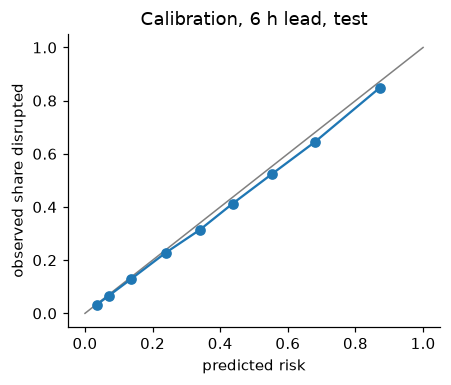

,predicted,observed,flights
bin,,,
"(-0.001, 0.05]",0.035,0.033,92332
"(0.05, 0.1]",0.070,0.066,81167
"(0.1, 0.2]",0.135,0.128,83271
"(0.2, 0.3]",0.239,0.228,45969
"(0.3, 0.4]",0.340,0.315,21049
"(0.4, 0.5]",0.437,0.413,19002
"(0.5, 0.6]",0.553,0.524,9418
"(0.6, 0.8]",0.680,0.645,11557
"(0.8, 1.0]",0.871,0.848,1373


,ROC-AUC,PR-AUC,Brier,precision@10% alerts,recall@10% alerts
normal weather at departure hour,0.783,0.411,0.104,0.481,0.346
IFR/thunderstorm at departure hour,0.828,0.672,0.150,0.799,0.285


,share of gain
Scheduled turn time,0.1552
Destination,0.1533
Airline,0.0922
Departure hour (local),0.0845
LAMP lightning probability,0.0817
Month,0.0358
LAMP convection probability,0.0292
Share of >45 min departures (at issue),0.0178
Avg departure delay (at issue),0.0171
TAF headwind on runway,0.0158


In [20]:
# Calibration and weather-day performance at 6 h lead
d6 = FTE[6][FTE[6].airport.isin(TRAIN_AIRPORTS)].copy()
d6["p"] = iso.predict(clf.predict(d6[CLF_FEATURES]))
d6["bin"] = pd.cut(d6.p, [0, .05, .1, .2, .3, .4, .5, .6, .8, 1], include_lowest=True)
calib = d6.groupby("bin", observed=True).agg(predicted=("p", "mean"), observed=("disrupted_45", "mean"), flights=("p", "size"))
wxday = d6.groupby((d6.met_cat_at_H >= 2) | (d6.met_ts_at_H == 1)).apply(
    lambda s: pd.Series(clf_metrics(s.disrupted_45.values, s.p.values)), include_groups=False)
wxday.index = ["normal weather at departure hour", "IFR/thunderstorm at departure hour"]
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.plot([0, 1], [0, 1], color="grey", lw=1); ax.plot(calib.predicted, calib.observed, marker="o")
ax.set(xlabel="predicted risk", ylabel="observed share disrupted", title="Calibration, 6 h lead, test")
plt.tight_layout(); plt.show()
display(calib.round(3)); display(wxday.round(3))
METRICS["clf_calibration_lead6"] = calib.reset_index(drop=True).round(4).to_dict(orient="records")
METRICS["clf_by_weather_lead6"] = wxday.round(4).reset_index().to_dict(orient="records")

cg = pd.Series(clf.feature_importance("gain"), index=CLF_FEATURES)
cgrp = {f: g for g, fs in CLF_GROUPS.items() for f in fs}
METRICS["clf_importance_groups"] = (cg.groupby(cgrp).sum() / cg.sum()).round(3).to_dict()
METRICS["clf_importance_top"] = {C.label(k): round(v, 4) for k, v in (cg / cg.sum()).sort_values(ascending=False).head(15).items()}
display(pd.Series(METRICS["clf_importance_top"]).to_frame("share of gain"))

## 7. Where the model fails, and why

We take the 100 test hours (busy, 6 h lead) where the model was **most over-optimistic** (forecast far above what landed) and label the likely cause from what was observed afterwards.

In [21]:
t = TE[(TE.lead_h == 6) & (TE.busy == 1)].copy()
t["miss"] = t.pred - t.y_arr
worst = t.nlargest(100, "miss").copy()

def window_flags(row, back_from, back_to):
    m = metars[row.airport].loc[row.hour - pd.Timedelta(hours=back_from): row.hour - pd.Timedelta(hours=back_to)]
    return {"ts": m.met_ts.max() == 1, "winter": (m.met_snow.max() == 1) | (m.met_fz.max() == 1), "ifr": m.met_cat.max() >= 2}

now = pd.DataFrame([window_flags(r, 2, 0) for _, r in worst.iterrows()], index=worst.index)
before = pd.DataFrame([window_flags(r, 8, 3) for _, r in worst.iterrows()], index=worst.index)
ts_fc = (worst.taf_any_ts.fillna(0) > 0) | (worst.lamp_ltg_prob.fillna(0) >= 20)
winter_fc = (worst.taf_snow.fillna(0) > 0) | (worst.taf_fz.fillna(0) > 0)
worst["likely cause"] = np.select(
    [now.winter & winter_fc, now.winter, now.ts & ~ts_fc, now.ts, now.ifr,
     before.ts | before.winter | before.ifr, worst.dep_disrupted_rate > 0.3],
    ["winter precipitation / icing: forecast, impact under-estimated", "winter precipitation / icing: not forecast",
     "thunderstorm: not forecast by TAF or LAMP", "thunderstorm: forecast, impact under-estimated", "low ceiling / visibility",
     "recovery after earlier weather (backlog, crews out of position)",
     "no local weather: system-wide disruption (en-route weather, IT, staffing)"],
    default="unexplained")
causes = worst["likely cause"].value_counts().to_frame("hours")
display(causes)
METRICS["failure_causes_top100"] = causes["hours"].to_dict()
FAIL_COLS = ["airport", "hour", "issue_utc", "arr_sched", "y_arr", "pred", "lo", "hi", "taf_raw", "ovl_raw",
             "lamp_ltg_prob", "met_ts_at_H", "met_cat_at_H", "met_winter_at_H", "likely cause"]
display(worst[FAIL_COLS].head(8))

# Also: false alarms (model expected a big drop that never came)
t["false_alarm"] = (t.pred < 0.8 * t.arr_sched) & (t.y_arr >= 0.95 * t.arr_sched)
METRICS["false_alarm_share_busy_lead6"] = float(t.false_alarm.mean())
print(f"False alarms (forecast >20% drop, actual within 5% of schedule): {t.false_alarm.mean():.2%} of busy hours")

,hours
likely cause,
unexplained,40
"thunderstorm: forecast, impact under-estimated",21
"winter precipitation / icing: forecast, impact under-estimated",11
"recovery after earlier weather (backlog, crews out of position)",9
thunderstorm: not forecast by TAF or LAMP,7
"no local weather: system-wide disruption (en-route weather, IT, staffing)",6
low ceiling / visibility,4
winter precipitation / icing: not forecast,2


,airport,hour,issue_utc,arr_sched,y_arr,pred,lo,hi,taf_raw,ovl_raw,lamp_ltg_prob,met_ts_at_H,met_cat_at_H,met_winter_at_H,likely cause
403733,KDFW,2025-01-10 01:00:00+00:00,2025-01-09 19:00:00+00:00,84,0,58.563402,24.532093,72.380821,FM092200 11006KT 2SM -PLRA OVC006,NaN,0.0,0.0,2.0,1.0,"winter precipitation / icing: forecast, impact..."
218043,KATL,2025-06-28 00:00:00+00:00,2025-06-27 18:00:00+00:00,63,0,57.590964,35.588890,70.108696,27005KT P6SM SCT030 SCT150,TEMPO 2721/2801 VRB15G25KT 4SM TSRA BR BKN025CB,14.0,1.0,2.0,0.0,"thunderstorm: forecast, impact under-estimated"
199333,KATL,2025-04-11 01:00:00+00:00,2025-04-10 19:00:00+00:00,77,8,61.890979,50.060061,72.428442,FM110000 23007KT P6SM -SHRA BKN060 OVC120,NaN,9.0,1.0,0.0,0.0,thunderstorm: not forecast by TAF or LAMP
218053,KATL,2025-06-28 01:00:00+00:00,2025-06-27 19:00:00+00:00,88,12,65.756613,47.689111,81.620481,27005KT P6SM SCT030 SCT150,NaN,17.0,1.0,2.0,0.0,thunderstorm: not forecast by TAF or LAMP
403653,KDFW,2025-01-09 17:00:00+00:00,2025-01-09 11:00:00+00:00,74,2,55.673128,28.818036,70.769124,FM091700 12005KT 1SM -RASNPL OVC004,NaN,0.0,0.0,3.0,1.0,"winter precipitation / icing: forecast, impact..."
177613,KATL,2025-01-10 13:00:00+00:00,2025-01-10 07:00:00+00:00,82,16,69.589685,53.088273,77.077656,FM101200 11004KT 5SM -SNPL OVC025,TEMPO 1013/1015 3SM -SNPL SCT010 BKN015 BKN025,0.0,0.0,2.0,1.0,"winter precipitation / icing: forecast, impact..."
416673,KDFW,2025-03-04 23:00:00+00:00,2025-03-04 17:00:00+00:00,72,3,55.053916,41.698430,73.613138,FM042100 28033G47KT 5SM BLDU BKN100,NaN,0.0,0.0,0.0,0.0,low ceiling / visibility
447903,KDFW,2025-07-13 02:00:00+00:00,2025-07-12 20:00:00+00:00,88,3,53.555359,20.280020,73.491536,FM130000 19013KT P6SM VCTS BKN050CB,PROB30 1300/1304 5SM -TSRA,14.0,1.0,0.0,0.0,"thunderstorm: forecast, impact under-estimated"


False alarms (forecast >20% drop, actual within 5% of schedule): 0.91% of busy hours


## 8. Warning lead time before NOAA-logged storms

NOAA Storm Events are compiled **after** the fact, so we use them only to score the model, never as inputs. For each convective or winter event near an airport during the test period, we ask: **how far ahead did the model first warn of a capacity drop during the event?**

In [22]:
storms = pd.read_parquet(EXT / "storms" / "storm_events_airports.parquet")
WX_TYPES = ["Thunderstorm Wind", "Hail", "Heavy Rain", "Flash Flood", "Tornado", "Lightning", "Winter Storm",
            "Ice Storm", "Winter Weather", "Heavy Snow", "Dense Fog", "High Wind", "Strong Wind"]
st = storms[storms.EVENT_TYPE.isin(WX_TYPES)]
st = st[(st.begin_utc >= pd.Timestamp(SPLITS["test"][0], tz="UTC")) & (st.begin_utc < pd.Timestamp(SPLITS["test"][1], tz="UTC"))]
ep = (st.groupby(["airport", "EPISODE_ID"]).agg(begin=("begin_utc", "min"), end=("end_utc", "max"),
      types=("EVENT_TYPE", lambda s: ", ".join(sorted(set(s)))), n_events=("EVENT_ID", "size")).reset_index())

allte = aar[aar.split == "test"].copy()
allte["pred"] = aar_model.predict(allte[AAR_FEATURES]) * allte.nominal
allte["lo"], allte["hi"] = bands(allte)
records = []
for _, e in ep.iterrows():
    hrs = allte[(allte.airport == e.airport) & (allte.hour >= e.begin.floor("h")) & (allte.hour <= e.end.ceil("h")) & (allte.busy == 1)]
    if hrs.empty:
        continue
    impact = (hrs[hrs.lead_h == 3].y_arr < 0.8 * hrs[hrs.lead_h == 3].arr_sched).any()
    def first_warning(cond):
        leads = hrs.loc[cond(hrs), "lead_h"]
        return int(leads.max()) if len(leads) else 0
    records.append({"airport": e.airport, "begin_utc": e.begin, "types": e.types, "capacity_dropped": bool(impact),
                    "model_warning_h": first_warning(lambda h: h.pred < ALERT_RATIO * h.arr_sched),
                    "taf_warning_h": first_warning(lambda h: (h.taf_any_ts.fillna(0) > 0) | (h.taf_worst_cat.fillna(0) >= 2))})
lt = pd.DataFrame(records)
hit = lt[lt.capacity_dropped]
lt_summary = pd.DataFrame({
    "episodes with a capacity drop": [len(hit)] * 2,
    "warned ≥ 3 h ahead": [(hit.model_warning_h >= 3).mean(), (hit.taf_warning_h >= 3).mean()],
    "warned ≥ 6 h ahead": [(hit.model_warning_h >= 6).mean(), (hit.taf_warning_h >= 6).mean()],
    "median warning (h)": [hit.model_warning_h.median(), hit.taf_warning_h.median()],
}, index=["Model alert (forecast < 85% of schedule)", "TAF says thunderstorm or IFR"]).round(3)
display(lt_summary)
print(f"{len(lt)} storm episodes near the airports in busy hours, {len(hit)} with a measurable capacity drop")
METRICS["storm_lead_time"] = lt_summary.reset_index().to_dict(orient="records")

,episodes with a capacity drop,warned ≥ 3 h ahead,warned ≥ 6 h ahead,median warning (h)
Model alert (forecast < 85% of schedule),50,0.94,0.90,12.0
TAF says thunderstorm or IFR,50,0.82,0.78,12.0


55 storm episodes near the airports in busy hours, 50 with a measurable capacity drop


## 9. Impact estimate: moving holding from the air to the ground

We use a simple hourly queue model to replay each test-period hour at ATL and DFW (assumptions below).
* **Demand:** each operated flight at the time it would have landed with no arrival delay. **Capacity:** what actually landed in hours where landings fell > 20% below schedule (a real reduction), otherwise the airport's nominal rate.
* **Reactive (today):** every flight departs on schedule. Any excess queues **in the air** (holding).
* **Proactive (our model):** when the forecast issued *L* hours earlier is more than 10% below demand, flights are held **on the ground at their origin** to match the forecast rate (a Ground Delay Program). If the forecast was too optimistic, the remaining excess still holds in the air.
* **Proactive, band-aware:** same trigger, but the GDP rate is set at the optimistic end of the 80% band. Fewer flights are held on the ground, which limits the cost of false alarms. This is a way of using the uncertainty band in the decision.
* **TAF rule:** a GDP at the TAF-rule rate whenever the TAF says thunderstorm or IFR.
* **Perfect foresight:** the same, using the true capacity. This is the upper bound.

Fuel and CO₂ use cited rates (EUROCONTROL Standard Inputs: 35.2 kg/min narrow-body holding; ICAO: 3.16 kg CO₂/kg fuel). Ground delay is assumed to be at the gate with engines off.

**These are estimates from a simplified model.** Real operations already use GDPs, so the true benefit over today's practice is smaller than the gap to the "reactive" scenario.

In [23]:
# Demand: when each operated flight would have landed with no arrival delay (early flights keep their earliness).
# Capacity: what landed in hours where landings fell > 20% below schedule (a real reduction); otherwise at least the
# airport's nominal rate, because quiet hours land fewer flights than the runways could accept.
def unimpeded_demand(airport):
    a = flights[(flights.DEST == C.iata_of(airport)) & flights.wheels_on_utc.notna()]
    t = a.wheels_on_utc - pd.to_timedelta(a.ARR_DELAY.clip(lower=0), unit="m")
    return t.dt.floor("h").value_counts()

def scenario(airport, lead, which):
    d = allte[(allte.airport == airport) & (allte.lead_h == lead)].sort_values("hour")
    pan = panels[airport].reindex(d.hour)
    demand = unimpeded_demand(airport).reindex(d.hour, fill_value=0).values.astype(float)
    reduced = (pan.arr_actual < 0.8 * pan.arr_sched) & (pan.arr_sched >= 0.4 * nominal[airport])
    cap = np.where(reduced, pan.arr_actual, np.maximum(pan.arr_actual, nominal[airport])).astype(float)
    if which == "reactive":
        planned = None
    elif which == "model":
        planned = np.where(d.pred.values < ALERT_RATIO * d.arr_sched.values, d.pred.values, np.inf)
    elif which == "model_confident":   # same trigger, but plan at the optimistic end of the 80% band (hold fewer flights)
        planned = np.where(d.pred.values < ALERT_RATIO * d.arr_sched.values, d.hi.values, np.inf)
    elif which == "taf_rule":
        sig = ((d.taf_any_ts.fillna(0) > 0) | (d.taf_worst_cat.fillna(0) >= 2)).values
        planned = np.where(sig, d.b_taf.values, np.inf)
    else:  # perfect foresight
        planned = np.where(cap < 0.9 * demand, cap, np.inf)
    g, a, _ = C.queue_sim(demand, cap, planned)
    return g, a

allte["taf_class"] = taf_class(allte)
allte["b_taf"] = allte.arr_sched * allte.taf_class.map(TAF_FACTORS).fillna(1)
imp = []
for ap in TRAIN_AIRPORTS:
    for lead in (3, 6):
        for which in ("reactive", "model", "model_confident", "taf_rule", "perfect"):
            g, a = scenario(ap, lead, which)
            imp.append({"airport": ap, "lead_h": lead, "scenario": which, "ground_min": g, "airborne_min": a})
imp = pd.DataFrame(imp)
base = imp[imp.scenario == "reactive"].set_index(["airport", "lead_h"]).airborne_min
imp["airborne_saved_min"] = imp.apply(lambda r: base[(r.airport, r.lead_h)] - r.airborne_min, axis=1)
imp["fuel_saved_t"] = imp.airborne_saved_min * C.FUEL_HOLD_KG_MIN / 1000
imp["co2_saved_t"] = imp.fuel_saved_t * C.CO2_PER_KG_FUEL
imp["total_delay_change_min"] = imp.ground_min + imp.airborne_min - imp.apply(lambda r: base[(r.airport, r.lead_h)], axis=1)
display(imp.round(0))
METRICS["impact"] = imp.round(1).to_dict(orient="records")
METRICS["impact_assumptions"] = {"fuel_hold_kg_min": C.FUEL_HOLD_KG_MIN, "co2_per_kg_fuel": C.CO2_PER_KG_FUEL,
                                 "block_cost_usd_min": C.BLOCK_COST_USD_MIN, "period": "2025-01-01 to 2025-07-30"}

,airport,lead_h,scenario,ground_min,airborne_min,airborne_saved_min,fuel_saved_t,co2_saved_t,total_delay_change_min
0,KATL,3,reactive,0.0,271020.0,0.0,0.0,0.0,0.0
1,KATL,3,model,130456.0,247116.0,23904.0,841.0,2659.0,106553.0
2,KATL,3,model_confident,10420.0,265524.0,5496.0,193.0,611.0,4924.0
3,KATL,3,taf_rule,423331.0,311934.0,-40914.0,-1440.0,-4551.0,464245.0
4,KATL,3,perfect,188880.0,82140.0,188880.0,6649.0,21010.0,0.0
5,KATL,6,reactive,0.0,271020.0,0.0,0.0,0.0,0.0
6,KATL,6,model,132162.0,247145.0,23875.0,840.0,2656.0,108287.0
7,KATL,6,model_confident,10301.0,265944.0,5076.0,179.0,565.0,5224.0
8,KATL,6,taf_rule,452463.0,325248.0,-54228.0,-1909.0,-6032.0,506691.0
9,KATL,6,perfect,188880.0,82140.0,188880.0,6649.0,21010.0,0.0


## 10. Save models and dashboard data

In [24]:
aar_model.save_model(str(MODEL_DIR / "aar_p50.txt"))
q_models[0.1].save_model(str(MODEL_DIR / "aar_q10.txt"))
q_models[0.9].save_model(str(MODEL_DIR / "aar_q90.txt"))
clf.save_model(str(MODEL_DIR / "delay_clf.txt"))
main.save_model(str(MODEL_DIR / "delay_main.txt"))
joblib.dump(miso, MODEL_DIR / "delay_main_calibrator.joblib")
mcols = ["airport", "hour", "sched_utc", "sched_dep_utc", "is_arrival", "OP_UNIQUE_CARRIER", "OP_CARRIER_FL_NUM", "TAIL_NUM",
         "ORIGIN", "DEST", "DEP_DELAY", "ARR_DELAY", "CANCELLED", "DIVERTED", "y45", "in_sched_arr", "in_actual_dep",
         "in_dep_delay", "in_origin", "own_actual_dep", "dep_hour_local"] + C.MAIN_STATIC
hub[hub.split == "test"][list(dict.fromkeys(mcols))].to_parquet(MODEL_DIR / "test_hub_flights.parquet", index=False)
joblib.dump(iso, MODEL_DIR / "delay_calibrator.joblib")
(MODEL_DIR / "conformal.json").write_text(json.dumps({"main_threshold": THR, "alpha": ALPHA, "per_lead": CONFORMAL, "taf_factors": TAF_FACTORS,
                                                      "alert_ratio": ALERT_RATIO, "nominal": nominal, "headings": HEADINGS}))

# Forecast rows for the test period (all airports, all leads): the dashboard replays these
keep = (["airport", "hour", "lead_h", "issue_utc", "split", "nominal", "y_arr", "arr_sched", "dep_disrupted_rate", "busy",
         "wx_impacted", "met_cat_at_H", "met_ts_at_H", "met_winter_at_H", "pred", "lo", "hi", "b_sched", "b_clim", "b_persist", "b_taf",
         "taf_class", "taf_raw", "ovl_raw", "issue", "runtime"] + AAR_FEATURES)
allte["b_persist"] = allte.arr_sched * allte.rt_ratio.fillna(1).clip(0, 1.3)
allte[list(dict.fromkeys(keep))].to_parquet(MODEL_DIR / "aar_test.parquet", index=False)

# History for trends (hourly, all airports)
hist = pd.concat([panels[a].join(metars[a][["met_cat", "met_ts", "met_crosswind_kt", "met_tailwind_kt", "met_wxtext"]]) for a in AIRPORTS])
hist.reset_index().to_parquet(MODEL_DIR / "hourly_history.parquet", index=False)

# Analog pool: past forecast situations (6 h lead) to show "similar days" next to each prediction
ANALOG_FEATS = ["taf_worst_cat", "taf_any_ts", "lamp_ltg_prob", "lamp_conv_prob", "taf_crosswind_kt", "taf_tailwind_kt",
                "taf_vis_sm", "taf_ceiling_ft", "hour_local", "sched_arr_n"]
pool = aar[(aar.split.isin(["train", "val"])) & (aar.lead_h == 6)][["airport", "hour", "y_arr", "arr_sched", "taf_raw", "ovl_raw"] + ANALOG_FEATS]
pool.to_parquet(MODEL_DIR / "analog_pool.parquet", index=False)

# Test departures (static info + inbound aircraft): the dashboard scores them live at any issue time
dcols = ["airport", "hour", "sched_dep_utc", "OP_UNIQUE_CARRIER", "OP_CARRIER_FL_NUM", "TAIL_NUM", "DEST", "DEP_DELAY",
         "CANCELLED", "DIVERTED", "disrupted_45", "in_sched_arr", "in_actual_dep", "in_dep_delay", "in_origin"] + C.CLF_STATIC
dep[dep.split == "test"][list(dict.fromkeys(dcols))].to_parquet(MODEL_DIR / "test_departures.parquet", index=False)
lt.to_parquet(MODEL_DIR / "storm_lead_times.parquet", index=False)
worst[FAIL_COLS].to_parquet(MODEL_DIR / "failure_cases.parquet", index=False)
(MODEL_DIR / "metrics.json").write_text(json.dumps(METRICS, indent=2, default=str))
for p in sorted(MODEL_DIR.iterdir()):
    print(f"{p.name:32s} {p.stat().st_size / 1e6:7.1f} MB")

aar_p50.txt                          7.0 MB
aar_q10.txt                          2.2 MB
aar_q90.txt                          2.1 MB
aar_test.parquet                    11.5 MB
analog_pool.parquet                  0.8 MB
conformal.json                       0.0 MB
delay_calibrator.joblib              0.0 MB
delay_clf.txt                        3.3 MB
delay_main.txt                       3.6 MB
delay_main_calibrator.joblib         0.0 MB
failure_cases.parquet                0.0 MB
hourly_history.parquet               1.7 MB
metrics.json                         0.0 MB
storm_lead_times.parquet             0.0 MB
test_departures.parquet             13.4 MB
test_hub_flights.parquet            32.0 MB


## 11. Summary and limitations

See the metric tables above (also saved to `data/model/metrics.json` and shown in the dashboard's **Model performance** tab).

**Limitations to state openly**
* **The label is runway throughput, not the FAA-called AAR.** In quiet hours throughput is below capacity, so we score "busy" and "weather-impacted" hours separately. FAA ASPM data (login required) would give the official rate.
* **Fixed runway heading per hub** (the brief's assumption). Real airports switch runway direction when the tailwind gets too strong, so our tailwind features are pessimistic.
* **Pop-up convection is the main failure:** storms that neither the TAF nor LAMP forecast cannot be anticipated from these inputs. Radar nowcasts (MRMS) or HRRR model output would be the next inputs to add.
* **System-wide disruptions** (airline IT outages, ATC staffing, en-route weather elsewhere) are outside local weather and show up as unexplained misses.
* **The impact numbers come from a simple queue model** and are upper-bound estimates against a no-GDP counterfactual.